# Q2. Discovery and interpretation of mutational signatures

The supplied data contain 96 mutation type and 193 samples. The COSMIC v3.3.1 GRCh38 catalogue contains 79 reference signatures.

KL-NMF analysis using Salamander 0.3.2

## 0. Load data

In [7]:
from pathlib import Path
from importlib.metadata import version
import os, sys, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import salamander
from IPython.display import display
from scipy.optimize import nnls
from scipy.stats import spearmanr
SEED = 0
DATA_DIR = Path(".")
print("Python:", sys.version.split()[0])
for package in ["salamander-learn", "numpy", "pandas", "scipy", "scikit-learn"]:
    print(f"{package}: {version(package)}")
print(DATA_DIR.resolve())
print(DATA_DIR.exists())
print(list(DATA_DIR.glob("*.csv")))



Python: 3.11.16
salamander-learn: 0.3.2
numpy: 1.24.4
pandas: 1.5.3
scipy: 1.15.3
scikit-learn: 1.3.2
/Users/tanxin/Jobs/postdoc/AEGIS/takehomequestions/Q2
True
[]


In [9]:
# load the mutation catalogue. (mutation type) x (cancer patients)
counts = pd.read_csv(DATA_DIR / "pcawg_breast_sbs_appended.csv", index_col=0)
print(counts.shape)
# load the reference COSMIC signatures
catalog = pd.read_csv(DATA_DIR / "COSMIC_v3.3.1_SBS_GRCh38.csv", index_col=0)

print(catalog.shape)


(96, 193)
(96, 79)


In [16]:
counts.head()

,SP10084,SP10150,SP10470,SP10563,SP10635,SP10944,SP11045,SP11171,SP11235,SP116331,...,SP9251,SP9433,SP9481,SP96147,SP96163,SP96511,SP9816,SP9930,SP9979,SP41XX
SBS,,,,,,,,,,,,,,,,,,,,,
A[C>A]A,239,61,218,56,35,144,28,153,78,125,...,94,47,45,77,139,268,133,166,32,1065.0
A[C>A]C,199,47,169,33,23,111,31,116,60,62,...,60,36,33,41,106,210,108,159,19,1463.0
A[C>A]G,28,4,26,3,8,19,3,22,10,15,...,10,9,7,10,17,38,17,20,3,620.0
A[C>A]T,222,34,194,22,24,94,21,125,43,47,...,72,34,26,36,115,209,136,120,23,891.0
C[C>A]A,163,44,206,41,24,90,28,110,78,104,...,57,44,31,50,102,230,120,176,15,1070.0


In [17]:
catalog.head()

,SBS1,SBS2,SBS3,SBS4,SBS5,SBS6,SBS7a,SBS7b,SBS7c,SBS7d,...,SBS86,SBS87,SBS88,SBS89,SBS90,SBS91,SBS92,SBS93,SBS94,SBS95
Type,,,,,,,,,,,,,,,,,,,,,
A[C>A]A,0.000876,5.790059e-07,0.020920,0.042451,0.012052,0.000425,0.000067,0.002344,0.004841,0.000040,...,0.002968,0.008946,1.004268e-18,0.032297,0.002222,0.002934,0.011396,0.011628,0.015677,0.038614
A[C>A]C,0.002220,1.455045e-04,0.016343,0.032990,0.009337,0.000516,0.000177,0.000457,0.001135,0.000754,...,0.003735,0.004490,9.890296e-19,0.017495,0.000704,0.052013,0.009653,0.008011,0.024523,0.017212
A[C>A]G,0.000180,5.361861e-05,0.001808,0.016116,0.001908,0.000053,0.000073,0.000192,0.000388,0.000257,...,0.000398,0.006357,1.031355e-18,0.009971,0.000144,0.000209,0.004851,0.001817,0.001627,0.008632
A[C>A]T,0.001265,9.759122e-05,0.012265,0.029663,0.006636,0.000180,0.000249,0.000714,0.001964,0.004051,...,0.003639,0.004941,1.737757e-03,0.020818,0.001771,0.000130,0.007800,0.008457,0.011141,0.023409
C[C>A]A,0.000305,2.053143e-04,0.022376,0.080269,0.007379,0.001800,0.000451,0.001134,0.000108,0.014348,...,0.006076,0.008436,9.930026e-19,0.024492,0.001183,0.008071,0.018450,0.006456,0.079522,0.058394


In [18]:
OUTLIER = "SP41XX"
others  = [s for s in counts.columns if s != OUTLIER]
print(counts.shape, catalog.shape)
tot = counts.sum() ### total number of mutations in sample i 

print(f"{OUTLIER}: {int(tot[OUTLIER]):,} mutations; median of the other samples: {tot[others].median():.0f}"
      f" (~{tot[OUTLIER]/tot[others].median():.0f}x)")

other_median = tot[others].median()
fold_difference = tot[OUTLIER] / other_median
# print(f"Other samples median: {other_median:,}")


(96, 193) (96, 79)
SP41XX: 147,722 mutations; median of the other samples: 5050 (~29x)


In [19]:
counts.iloc[1, 2] # number of mutations in the second sample and third mutation type

169

Because `counts.sum()` uses `axis=0` by default, it sums the mutation counts down each column:

$$
T_j = \sum_{i=1}^{96} m_{ij},
$$

where:

- $m_{ij}$ is the number of mutations in mutation context $i$ for sample $j$.
- $T_j$ is the total number of mutations in sample $j$.
- The 96 rows represent the 96 trinucleotide mutation contexts.

## Q2.1. For each signature identified, find the closest one in the reference COSMIC set. Justify the usage of similarity metric you choose.
data:
model.signatures - signatures identified

catalog - known mutational signatures, retrieved from https://cancer.sanger.ac.uk/signatures/sbs/


In [20]:
# Check duplicates
assert counts.index.is_unique and catalog.index.is_unique

assert len(counts.index) == 96 and set(counts.index) == set(catalog.index)
# Channel labels are unique. There are 96 channels. Both matrices contain the same channels.
# The last line puts the reference matrix into exactly the same row order as the observed data.


catalog = catalog.loc[counts.index]
for frame in [counts, catalog]:
    assert np.isfinite(frame.to_numpy()).all()
    assert (frame.to_numpy() >= 0).all()
assert (counts.sum(axis=0) > 0).all()
print(f"Counts: {counts.shape[0]} SBS mutation types × {counts.shape[1]} samples")
print(f"Reference: {catalog.shape[1]} COSMIC signatures")

#These reject missing/infinite values, negative entries and samples containing no mutations.


Counts: 96 SBS mutation types × 193 samples
Reference: 79 COSMIC signatures


## Method recap (Alexandrov et al. 2013)

Each genome's 96-channel mutation catalog is modelled as a non-negative linear mixture of mutational processes:
**M ≈ P × E**, with `M` (96 × G) the observed catalogs, `P` (96 × N) the signatures (each a probability distribution over the 96 types), and `E` (N × G) the exposures (mutations caused by each process in each genome).
This is a blind-source-separation problem, solved with non-negative matrix factorization (NMF). We can use Salamander's KL-divergence NMF (`KLNMF`), which minimises a Poisson-like loss, whereas the paper minimises the Frobenius error.

Signature similarity is measured with cosine similarity, `sim(A, B) = Σ A_k B_k / (‖A‖ ‖B‖)`, in [0, 1]. The number of signatures N is chosen by bootstrap model selection, balancing reproducibility (silhouette width) against reconstruction error.


### Relationship between the Python objects and mathematical notation

The complete mutation-count matrix corresponds to:

$$
\texttt{counts} \longleftrightarrow \mathbf{M}
$$

The mutation-count vector for sample `SP41XX` corresponds to:

$$
\texttt{counts["SP41XX"]} \longleftrightarrow \mathbf{m}_g
$$

An individual mutation count for mutation type $i$ in sample $g$ corresponds to:

$$
\texttt{counts.loc[mutation\_type, "SP41XX"]}
\longleftrightarrow m_g^i
$$

Therefore, the total number of mutations in sample $g$ is:

$$
T_g = \sum_{i=1}^{96} m_g^i
$$

which is calculated for all samples in Python using:

```python
tot = counts.sum(axis=0)


$$
\texttt{counts}
\longleftrightarrow
\mathbf M_{96\times193}
$$

$$
\texttt{counts["SP41XX"]}
\longleftrightarrow
\mathbf m_g
$$

$$
\texttt{reference}
\longleftrightarrow
\mathbf P_{96\times79}
$$

$$
\texttt{NNLS\ coefficients}
\longleftrightarrow
\mathbf e_g
$$
### 4. NMF in the paper

The original paper treats mutational signature analysis as a **blind-source separation problem**:

$$
\mathbf{M} \approx \mathbf{P}\mathbf{E}.
$$

Only $\mathbf{M}$ is observed. Both $\mathbf{P}$ and $\mathbf{E}$ are unknown, so the authors use non-negative matrix factorization (NMF):

$$
(\hat{\mathbf{P}},\hat{\mathbf{E}})
=
\underset{\mathbf{P},\mathbf{E}\geq 0}
{\operatorname{argmin}}
\left\|
\mathbf{M}-\mathbf{P}\mathbf{E}
\right\|_F^2.
$$

The Frobenius reconstruction error is:

$$
\left\|
\mathbf{M}-\mathbf{P}\mathbf{E}
\right\|_F^2
=
\sum_{i=1}^{96}
\sum_{g=1}^{G}
\left(
m_g^i-\sum_{n=1}^{N}p_n^i e_g^n
\right)^2.
$$

A smaller reconstruction error means that the extracted signatures and exposures reproduce the observed mutation catalogs more accurately.

The paper compares this problem to a cocktail party:

- Mutational processes or signatures, $\mathbf{P}$: individual conversations
- Signature exposures, $\mathbf{E}$: loudness of each conversation
- Cancer samples: microphones
- Observed mutation catalogs, $\mathbf{M}$: mixed recordings

NMF attempts to separate the mixed recordings into their unknown underlying sources.

### 5. NNLS in the current analysis

The current analysis is different because the COSMIC signatures are already known.

The COSMIC signature matrix, $\mathbf{P}_{\mathrm{COSMIC}}$, is fixed. NNLS estimates only the exposure vector for each sample:

$$
\hat{\mathbf{e}}_g
=
\underset{\mathbf{e}_g\geq 0}
{\operatorname{argmin}}
\left\|
\mathbf{m}_g
-
\mathbf{P}_{\mathrm{COSMIC}}\mathbf{e}_g
\right\|_2^2.
$$

| Method | Known | Estimated |
|---|---|---|
| NMF extraction in the paper | $\mathbf{M}$ | Both $\mathbf{P}$ and $\mathbf{E}$ |
| COSMIC NNLS fitting | $\mathbf{M}$ and $\mathbf{P}_{\mathrm{COSMIC}}$ | Only $\mathbf{E}$ |

The NNLS coefficient vector $\mathbf{a}_j$ is equivalent to the exposure vector $\mathbf{e}_j$:

$$
\boxed{\mathbf{a}_j=\mathbf{e}_j}
$$

Both represent the contributions of the mutational signatures to sample $j$.

## 2.1.0 Outlier check

Before fitting anything, check outliers on the raw catalogs in two ways: **how many mutations** it has (burden) and **what they look like** (profile shape). NMF with a KL/Poisson loss works on raw counts, so a sample can dominate the fit through either.

,total SBS,x median,log10 z-score
SP41XX,147722,29.0,4.3
SP117369,55654,10.9,3.0
SP117011,36115,7.1,2.5
SP3631,31634,6.2,2.3
SP13036,25730,5.0,2.0
SP124197,23237,4.6,1.9


Median burden of the other samples: 5050;  SP41XX: 147,722.0  (29x; 10.1% of ALL mutations in the cohort)
Per Mb (assuming ~3.1 Gb): typical 1.6, SP41XX 47.7

Lowest cosine to the leave-one-out mean profile (median over samples = 0.907):


,cosine to others
SP41XX,0.419
SP13036,0.607
SP117011,0.681
SP117369,0.686
SP3631,0.697
SP117372,0.724


,SP41XX,median of others
SBS,,
C>A,10.7,17.1
C>G,7.2,14.1
C>T,22.3,36.5
T>A,39.7,10.3
T>C,11.2,15.3
T>G,9.0,6.6


,SP41XX %,others mean %,fold
SBS,,,
T[T>A]A,12.55,0.99,12.73
C[T>A]A,4.48,0.44,10.17
C[T>A]T,4.83,0.77,6.30
T[T>A]T,6.20,1.05,5.92
G[T>A]A,1.72,0.34,5.05
C[C>T]C,5.83,1.28,4.54
A[T>A]A,2.65,0.77,3.45
G[T>G]A,0.58,0.19,3.02


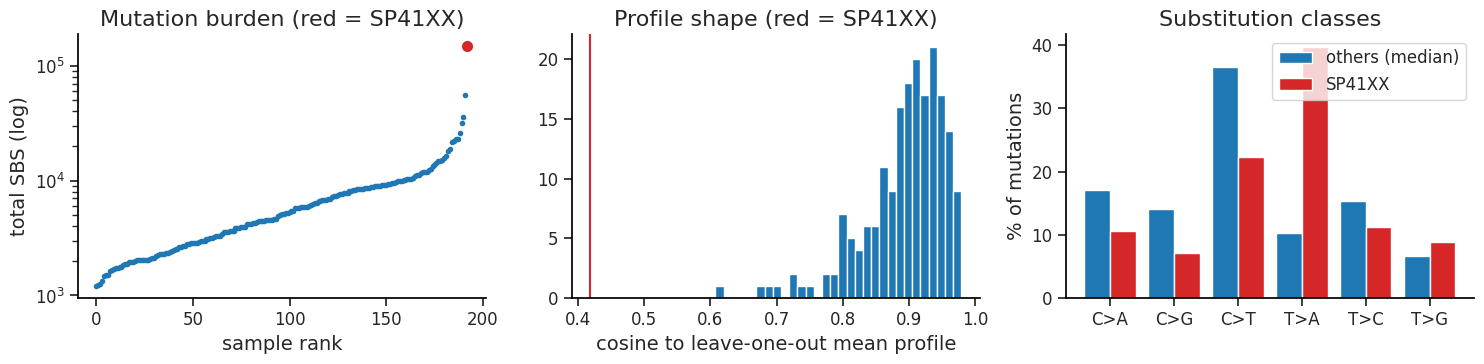

In [ ]:
## Analysis of mutation burden
### Compute cosine similarity function

def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

tot = counts.sum()
P_all = counts / tot                                   # per-sample profiles (proportions)

# (1) Burden
lt = np.log10(tot); z = (lt - lt.mean()) / lt.std()
q1, q3 = tot.quantile([.25, .75]); iqr = q3 - q1
burden = pd.DataFrame({"total SBS": tot.astype(int), "x median": (tot / tot.median()).round(1),
                       "log10 z-score": z.round(1)}).sort_values("total SBS", ascending=False)

## Display the top 6 samples with highest mutation burden
display(burden.head(6))

print(f"Median burden of the other samples: {tot[others].median():.0f};  SP41XX: {tot[OUTLIER]:,}  "
      f"({tot[OUTLIER]/tot[others].median():.0f}x; {tot[OUTLIER]/tot.sum():.1%} of ALL mutations in the cohort)")
print(f"Per Mb (assuming ~3.1 Gb): typical {tot[others].median()/3100:.1f}, SP41XX {tot[OUTLIER]/3100:.1f}")

# (2) cosine of each sample to the mean profile of all OTHER samples (leave-one-out)
loo = pd.Series({s_: cosine(P_all[s_].values, P_all.drop(columns=s_).mean(axis=1).values) for s_ in counts.columns})
print("\nLowest cosine to the leave-one-out mean profile (median over samples = %.3f):" % loo.median())
display(loo.sort_values().head(6).round(3).to_frame("cosine to others"))


# (3) six-class composition and most enriched mutation type
sub = counts.index.str[2:5] # collapse the 96 channels into six classes, then calculate their proportions
comp = counts.groupby(sub).sum() / tot
display((pd.DataFrame({OUTLIER: comp[OUTLIER], "median of others": comp[others].median(axis=1)}) * 100).round(1))
enr = pd.DataFrame({"SP41XX %": P_all[OUTLIER] * 100, "others mean %": P_all[others].mean(axis=1) * 100})
enr["fold"] = enr["SP41XX %"] / enr["others mean %"]
display(enr.sort_values("fold", ascending=False).head(8).round(2))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
r = tot.sort_values().reset_index(drop=True)
axs[0].semilogy(r.values, "o", ms=3); axs[0].semilogy([len(r) - 1], [r.iloc[-1]], "o", color="C3", ms=7)
axs[0].set_xlabel("sample rank"); axs[0].set_ylabel("total SBS (log)"); axs[0].set_title("Mutation burden (red = SP41XX)")
axs[1].hist(loo.drop(OUTLIER), bins=30); axs[1].axvline(loo[OUTLIER], color="C3"); axs[1].set_xlabel("cosine to leave-one-out mean profile")
axs[1].set_title("Profile shape (red = SP41XX)")
cl = comp.index; xx = np.arange(len(cl))
axs[2].bar(xx - 0.2, comp[others].median(axis=1) * 100, 0.4, label="others (median)"); axs[2].bar(xx + 0.2, comp[OUTLIER] * 100, 0.4, color="C3", label="SP41XX")
axs[2].set_xticks(xx); axs[2].set_xticklabels(cl); axs[2].set_ylabel("% of mutations"); axs[2].legend(); axs[2].set_title("Substitution classes")
plt.tight_layout(); plt.show()


### Findings
1. SP41XX has a significantly higher mutation burden compared to the median of the other samples. It has 147,722 SBSs, 29 times the median (5,050 in the other samples). It is the most extreme sample (log10 z score= 4.3).
2. SP41XX mutation profile is differnt from any other sample's. Its cosine to the rest of the cohort is 0.42, versus a typical 0.91.  SP41XX is the clearest outlier.
3. In SP41XX, T>A is **39.7%** of its substitutions (10.3% in other samples) while C>T drops to 22% (36.5%) and C>A to 11% (17%). The most enriched mutation type are **T[T>A]A (12.7x), C[T>A]A (10.2x), C[T>A]T (6.3x), T[T>A]T (5.9x)** and **C[C>T]C (4.5x)**.
4. About 97% of SP41XX's mutations are "extra" relative to a typical sample, and those extra mutations carry this unusual shape. So the two outlier signals are one phenomenon: a very large additional mutagenic exposure that is absent from the rest of the cohort. The enriched mutation type (T>A at TpTpA/TpTpT, C>T at CpCpC/CpCpT) are the ones that define the treatment signatures SBS90 and SBS31.
5.  With a Poisson/KL loss on raw counts, one sample holding 10% of all mutations and a unique profile pulls a whole signature towards itself. That is why SP41XX ends up with a private signature (Sig2), and why that signature can leak small exposures into other samples.

# 1. KL-NMF fit

### Same as the original notebook: 7 signatures a priori



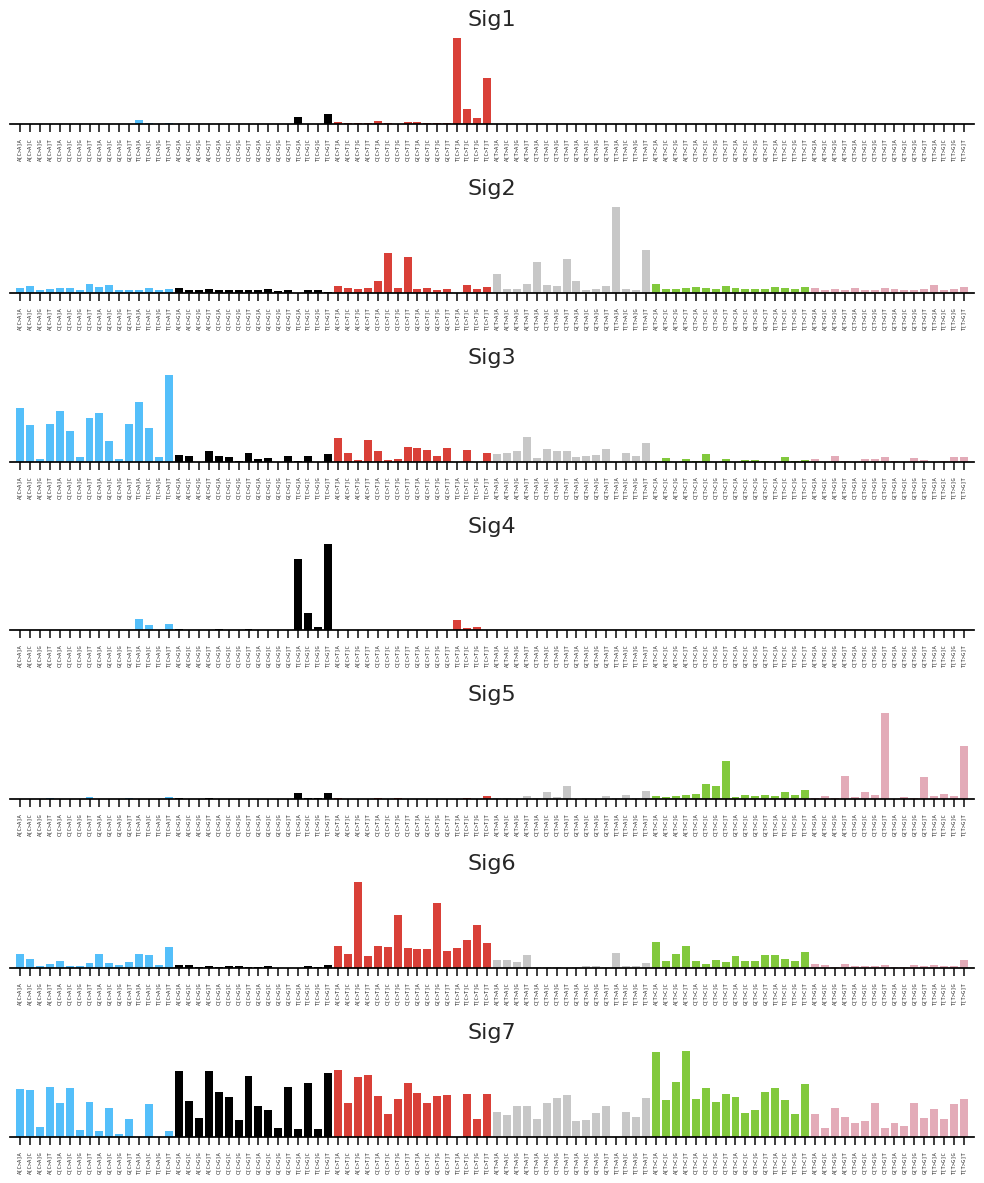

In [21]:
np.random.seed(0)
model = salamander.KLNMF(n_signatures=7, max_iterations=10000)
model.fit(counts, history=True)

signatures = model.signatures      # 96 x 7
exposures  = model.exposures       # 7 x 193
fig, axes = plt.subplots(7, 1, figsize=(10, 12))
model.plot_signatures(annotate_mutation_types=True, axes=axes)
plt.tight_layout(); plt.show()


In [22]:
## stability check across random initation

def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

stab = {}
for seed in range(1, 6):
    np.random.seed(seed)
    m = salamander.KLNMF(n_signatures=7, max_iterations=10000); m.fit(counts)
    stab[seed] = [max(cosine(signatures[s].values, m.signatures[t].values) for t in m.signatures)
                  for s in signatures]
pd.DataFrame(stab, index=signatures.columns).round(3)

,1,2,3,4,5
Sig1,1.0,1.0,1.0,1.0,1.0
Sig2,1.0,1.0,1.0,1.0,1.0
Sig3,1.0,1.0,1.0,1.0,1.0
Sig4,1.0,1.0,1.0,1.0,1.0
Sig5,1.0,1.0,1.0,1.0,1.0
Sig6,1.0,1.0,1.0,1.0,1.0
Sig7,1.0,1.0,1.0,1.0,1.0


## 1b. Choosing the number of signatures k (bootstrap model selection)

`n_signatures=7` was taken from the original notebook. Here we want to check whether it is reasonable, following Alexandrov et al. 2013:

1. Apply a **multinomial bootstrap** to each sample's mutation counts (the total number of mutations per sample is preserved).
2. For each k, run KL-NMF on B bootstrapped datasets.
3. Cluster the k signatures from all runs (Hungarian matching + re-centering) and use the mean cosine **silhouette width** as **stability** (1 = the same signatures are recovered every time).
4. Refit exposures on the original data with the averaged signatures and compute the **mean sample cosine distance** (reconstruction error; lower is better).

Choose the largest k for which stability is still high and the error has reached a plateau. Note: **without bootstrapping, different random seeds almost always give the same solution (stability is always 1), so that cannot be used to choose k.**

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import silhouette_samples

B = 20        # number of bootstrap runs (the paper uses 400-500). To save time we use a smaller number here
rng = np.random.default_rng(0) ## a seeded random generator used only for the bootstrap resampling
X = counts.values.astype(float)  ## the 96 × 193 count matrix as a plain float array.

### normlises each column of A and Bm to length 1, then multiplies.
def cos_mat_(A, Bm):
    An = A / np.linalg.norm(A, axis=0); Bn = Bm / np.linalg.norm(Bm, axis=0)
    return An.T @ Bn

### Given fixed signatures W, KL finds exposures H that best fit X under the KL (Poisson-like) loss:
def kl_refit(W, X, iters=1500):
    H = np.ones((W.shape[1], X.shape[1])) * X.sum(0) / W.shape[1]
    for _ in range(iters):
        H *= (W.T @ (X / (W @ H + 1e-12))) / W.sum(0)[:, None]
    return H
## Each iteration applies the standard multiplicative KL update: multiply H by (Wᵀ (X / (WH))) / (column sums of W). The 1e-12 avoids division by zero.


## paper's step 2:
# For each sample g, rng.multinomial(total_g, P[:, g]) redraws the same number of mutations, with each mutation assigned to a mutation type according to that sample's proportions.
## Therefore, this bootstrap_counts function generates a new count matrix by resampling each column according to its proportions.

def bootstrap_counts(X):
    P = X / X.sum(0)  ### turns each sample into its proportion
    return np.column_stack([rng.multinomial(int(X[:, g].sum()), P[:, g]) for g in range(X.shape[1])]).astype(float)



## The Main loop for selecting the number of signatures (k):
def select_k(X, ks=range(1, 11), B=20):
    res = {}
    for k in ks:
        sigs = []
        for b in range(B):
            np.random.seed(b) # seed the random number generator for reproducibility
            m = salamander.KLNMF(n_signatures=k, max_iterations=3000) # Fit B bootstrap NMFs. For each run, it resamples the data, fits KLNMF with k signatures, and keeps the 96 × k signature matrix.
            m.fit(pd.DataFrame(bootstrap_counts(X), index=counts.index)); sigs.append(m.signatures.values)
        ref = sigs[0]
        for _ in range(5):
            aligned = []
            for S_ in sigs: # Take the first run as a reference.For each run, linear_sum_assignment (the Hungarian algorithm) finds the one-to-one pairing of its signatures to the reference's that maximises total cosine similarity (the minus sign turns "maximise" into "minimise").
                _, c = linear_sum_assignment(-cos_mat_(ref, S_)); aligned.append(S_[:, c]) # Hungarian matching and re-centring (lining up signatures across runs)
            ref = np.mean([a / np.linalg.norm(a, axis=0) for a in aligned], axis=0)
        allS = np.hstack([a / np.linalg.norm(a, axis=0) for a in aligned]).T
        labels = np.tile(np.arange(k), B) ## Stability (reproducibility) All aligned signatures are stacked into a (k × B) × 96 matrix.
        if k > 1:
            sil = silhouette_samples(allS, labels, metric="cosine")
            stab = np.mean([sil[labels == j].mean() for j in range(k)])
        else:
            stab = 1.0
        P = np.mean(aligned, axis=0); P = P / P.sum(0)  # Final signatures. The aligned signatures are averaged and renormalised to sum to 1
        R = P @ kl_refit(P, X)  # Reconstruction error
        cd = 1 - np.sum(X * R, 0) / (np.linalg.norm(X, axis=0) * np.linalg.norm(R, axis=0))
        res[k] = (cd.mean(), stab)
    return pd.DataFrame(res, index=["mean_cosine_distance", "stability"]).T

sel_all  = select_k(X, B=B)
sel_excl = select_k(counts[others].values.astype(float), B=B)
display(pd.concat({"all samples": sel_all, "SP41XX removed": sel_excl}, axis=1).round(3))


all samples                 SP41XX removed          
   mean_cosine_distance stability mean_cosine_distance stability
1                 0.155     1.000                0.161     1.000
2                 0.070     1.000                0.055     1.000
3                 0.053     1.000                0.023     0.999
4                 0.023     0.999                0.019     0.999
5                 0.019     0.999                0.013     0.998
6                 0.013     0.999                0.011     0.935
7                 0.010     0.950                0.009     0.929
8                 0.009     0.931                0.009     0.732
9                 0.008     0.861                0.008     0.778
10                0.008     0.799                0.008     0.721

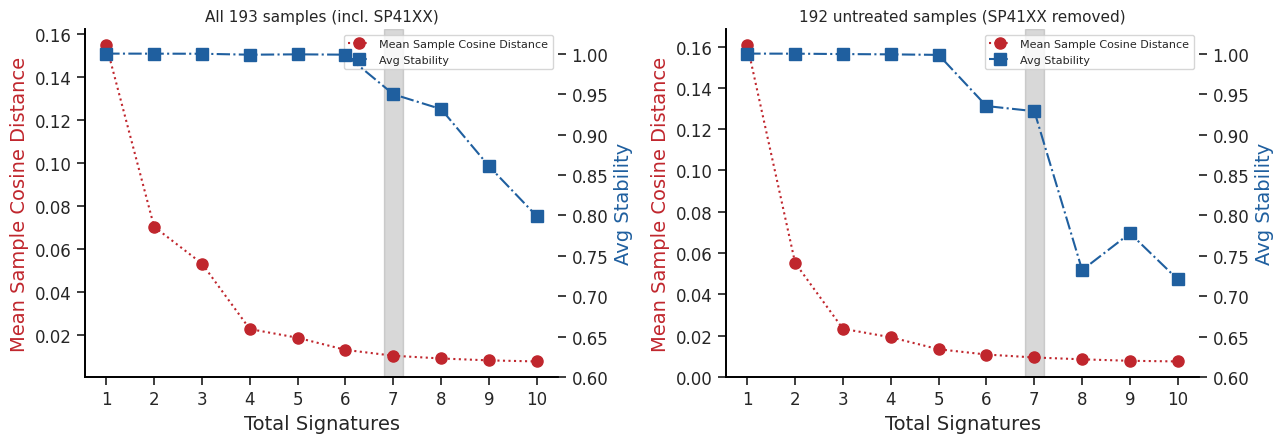

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (d, title) in zip(axs, [(sel_all, "All 193 samples (incl. SP41XX)"), (sel_excl, "192 untreated samples (SP41XX removed)")]):
    ks = d.index
    ax.plot(ks, d["mean_cosine_distance"], ":o", color="#c0262d", label="Mean Sample Cosine Distance")
    ax.set_ylabel("Mean Sample Cosine Distance", color="#c0262d")
    ax2 = ax.twinx(); ax2.plot(ks, d["stability"], "-.s", color="#1f5f9f", label="Avg Stability")
    ax2.set_ylabel("Avg Stability", color="#1f5f9f"); ax2.set_ylim(0.6, 1.03)
    ax.axvspan(6.8, 7.2, color="grey", alpha=.3); ax.set_xticks(ks); ax.set_xlabel("Total Signatures"); ax.set_title(title, fontsize=11)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8)
plt.tight_layout(); plt.show()

Stability stays close to 1 up to k=6,

## Q2.1 answers: closest COSMIC signature for each extracted signature
We want to use cosine similarity because of the following reasons:
1. Cosine similarity is scale-invariant. In the negative matrix factorization, the scale of fixed signatures W and exposures H is aribitrary (PXE and  cP x E/c). However, we  care about the shape of the 96-mutational type profile, not the mutation burden. Cosine similarity can compare direction only.
2. Signatures are non-negative, so cosine ranges in [0, 1], with 1=identical.  The original Alexandrov 2013 paper also uses cosine similairty and set the empirical threshold >0.95 as "accurately deciphered signatures" in Figure 3G.
3. For the other alternatives:
   - Pearson correlation centres each vector, but a signature is a probability distribution (mean always 1/96), so centring has no biological meaning, and it is still dominated by large peaks.
   - KL divergence is very unstable for COSMIC channels close to 0 (tiny values can change the top hit) and is asymmetric.
   - L1/L2 distances are affected by how flat a signature is and favour flat signatures.
Limitation of cosine similarity: dominated by the large peaks.


For each signature identfied, find the closest one in the reference COSMIC set:

In [23]:
# Cosine similarity matrix: 7 extracted signatures x all COSMIC signatures
A = signatures.values; B_ = catalog.values
cos_mat = pd.DataFrame((A.T @ B_) / np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(B_, axis=0)),
                       index=signatures.columns, columns=catalog.columns)

rows = []
for s in cos_mat.index:
    top = cos_mat.loc[s].sort_values(ascending=False)
    pear = pd.Series({k: np.corrcoef(signatures[s], catalog[k])[0, 1] for k in catalog}).idxmax()
    rows.append({"signature": s,
                 "best COSMIC": top.index[0], "cosine": round(top.iloc[0], 3),
                 "2nd": top.index[1], "cosine_2nd": round(top.iloc[1], 3),
                 "3rd": top.index[2], "cosine_3rd": round(top.iloc[2], 3),
                 "cosine >= 0.95 (paper)": bool(top.iloc[0] >= 0.95),
                 "Pearson best": pear})
best = pd.DataFrame(rows).set_index("signature")
best

,best COSMIC,cosine,2nd,cosine_2nd,3rd,cosine_3rd,cosine >= 0.95 (paper),Pearson best
signature,,,,,,,,
Sig1,SBS2,0.991,SBS7a,0.713,SBS30,0.485,True,SBS2
Sig2,SBS90,0.855,SBS47,0.584,SBS31,0.584,False,SBS90
Sig3,SBS18,0.904,SBS95,0.896,SBS36,0.844,False,SBS18
Sig4,SBS13,0.994,SBS86,0.533,SBS39,0.497,True,SBS13
Sig5,SBS17b,0.861,SBS9,0.698,SBS28,0.632,False,SBS17b
Sig6,SBS6,0.796,SBS1,0.794,SBS5,0.690,False,SBS1
Sig7,SBS3,0.919,SBS5,0.866,SBS40,0.814,False,SBS3


In [24]:
# Share of each of the six substitution classes, as a sanity check
sub6 = signatures.groupby(signatures.index.str[2:5]).sum()
(sub6 * 100).round(0).astype(int)

,Sig1,Sig2,Sig3,Sig4,Sig5,Sig6,Sig7
C>A,3,11,56,11,2,14,12
C>G,9,6,7,79,5,3,19
C>T,86,21,15,8,2,52,21
T>A,1,41,15,1,12,7,13
T>C,1,11,3,1,29,20,23
T>G,0,9,3,0,50,5,11


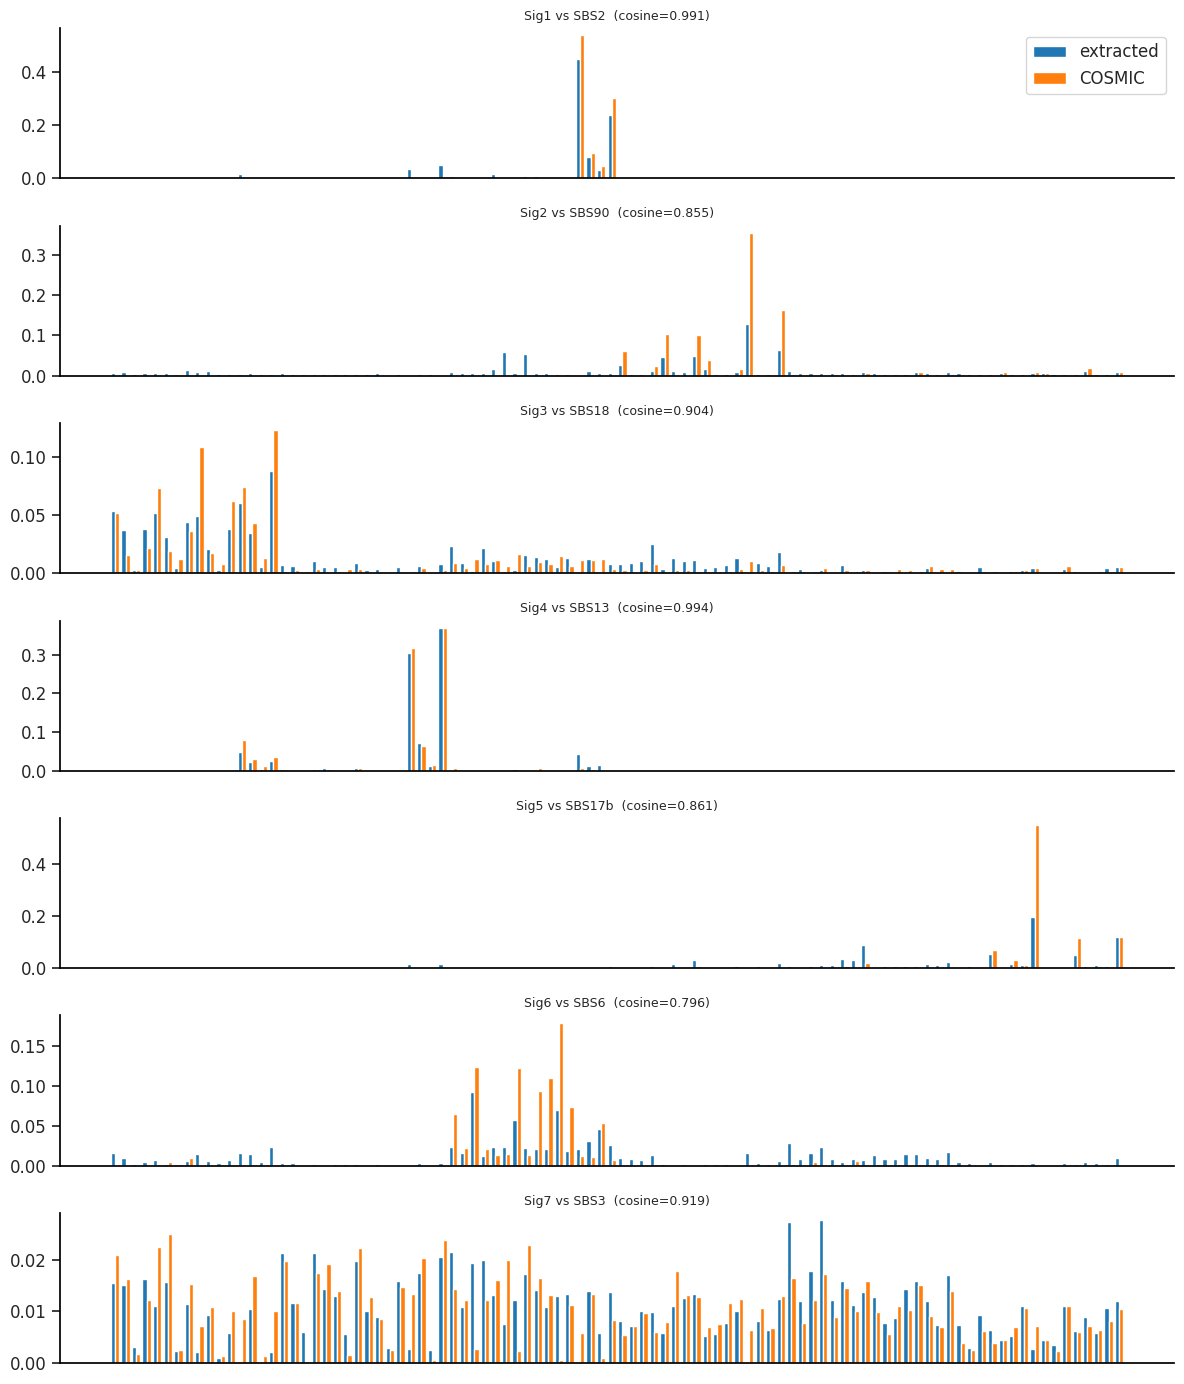

In [ ]:
# Visual check: each extracted signature next to its best COSMIC match
def plot_pair(ax, a, b, title):
    x = np.arange(96)
    ax.bar(x - 0.2, a, width=0.4, label="extracted"); ax.bar(x + 0.2, b, width=0.4, label="COSMIC")
    ax.set_title(title, fontsize=9); ax.set_xticks([])
fig, axes = plt.subplots(7, 1, figsize=(12, 14))
for ax, s in zip(axes, signatures.columns):
    k = best.loc[s, "best COSMIC"]
    plot_pair(ax, signatures[s].values, catalog[k].values, f"{s} vs {k}  (cosine={best.loc[s,'cosine']})")
axes[0].legend(); plt.tight_layout(); plt.show()


| Extracted | Closest COSMIC | Cosine | ≥ 0.95? | Interpretation |
|---|---|---|---|---|
| Sig1 | **SBS2** | 0.991 | yes | APOBEC (C>T at TpCpN) |
| Sig2 | **SBS90**  | 0.855 | no | Duocarmycin exposure |
| Sig3 | **SBS18** | 0.904 | no | Reactive oxygen species  |
| Sig4 | **SBS13** | 0.994 | yes | APOBEC (C>G at TpCpN) |
| Sig5 | **SBS17b** | 0.861 | no | Unknown, T>G-rich |
| Sig6 | **SBS6** | 0.796 | no| defective DNA mismatch repair and is found in microsatellite unstable tumours. |
| Sig7 | **SBS3** | 0.919 | no | Homologous-recombination deficiency  |

**Grade confidence by cosine** instead of treating every match as equally reliable:
   - ≥ 0.95: near-identical (Sig1 → SBS2, Sig4 → SBS13);
   - 0.85–0.95: probable, but possibly a composite or noisy signature (Sig7 → SBS3, Sig3 → SBS18, Sig5 → SBS17b, Sig2 → SBS90);
   - < 0.85: tentative (Sig6).

In [25]:
# Robustness checks for the Q2.1 matches. Extends the existing `best` table.
from scipy.spatial.distance import jensenshannon
from scipy.optimize import linear_sum_assignment

# (1) Baseline: cosine between pairs of *different* COSMIC signatures
B_n = catalog.values / np.linalg.norm(catalog.values, axis=0)
cosmic_pairs = (B_n.T @ B_n)[~np.eye(catalog.shape[1], dtype=bool)]
print(f"COSMIC pairwise cosine: median {np.median(cosmic_pairs):.2f}, "
      f"95th percentile {np.percentile(cosmic_pairs, 95):.2f}")

# (2) Gap between the best and second-best match (computed from unrounded cos_mat)
top2 = np.sort(cos_mat.values, axis=1)[:, -2:]
best["gap"] = pd.Series(top2[:, 1] - top2[:, 0], index=cos_mat.index).round(3)

# (3) Confidence grade
def confidence(c):
    return "near-identical" if c >= 0.95 else "probable" if c >= 0.85 else "tentative"
best["confidence"] = best["cosine"].apply(confidence)

# (4) Second robustness metric: Jensen-Shannon distance
#     (scipy normalises each vector to sum to 1; lower = more similar)
best["JS best"] = [
    pd.Series({k: jensenshannon(signatures[s].values, catalog[k].values) for k in catalog}).idxmin()
    for s in best.index
]

# (5) One-to-one Hungarian assignment (maximise total cosine)
r, c = linear_sum_assignment(-cos_mat.values)
best["Hungarian"] = pd.Series(cos_mat.columns[c], index=cos_mat.index[r])

# (6) Do the three metrics agree on the best match?
best["metrics agree"] = (best["best COSMIC"] == best["Pearson best"]) & (best["best COSMIC"] == best["JS best"])

best[["best COSMIC", "cosine", "2nd", "cosine_2nd", "gap", "confidence",
      "Pearson best", "JS best", "Hungarian", "metrics agree"]]

COSMIC pairwise cosine: median 0.12, 95th percentile 0.60


,best COSMIC,cosine,2nd,cosine_2nd,gap,confidence,Pearson best,JS best,Hungarian,metrics agree
signature,,,,,,,,,,
Sig1,SBS2,0.991,SBS7a,0.713,0.278,near-identical,SBS2,SBS2,SBS2,True
Sig2,SBS90,0.855,SBS47,0.584,0.271,probable,SBS90,SBS31,SBS90,False
Sig3,SBS18,0.904,SBS95,0.896,0.008,probable,SBS18,SBS95,SBS18,False
Sig4,SBS13,0.994,SBS86,0.533,0.461,near-identical,SBS13,SBS13,SBS13,True
Sig5,SBS17b,0.861,SBS9,0.698,0.164,probable,SBS17b,SBS9,SBS17b,False
Sig6,SBS6,0.796,SBS1,0.794,0.002,tentative,SBS1,SBS5,SBS6,False
Sig7,SBS3,0.919,SBS5,0.866,0.052,probable,SBS3,SBS3,SBS3,True


In [ ]:
# Forward-selection NNLS: start with no signatures and add the COSMIC signature
# that most improves the reconstruction cosine; stop when the gain < min_gain.
# Avoids the overfitting of fitting all 79 COSMIC signatures at once.

# x: the 96-channel profile to explain (an extracted signature like Sig2, or a sample’s counts).
# #catalog: the 79 COSMIC signatures (96 × 79 DataFrame), the candidates.
# min_gain=0.005: the stopping rule. A new signature must raise the reconstruction cosine by at least 0.005 to be kept.
# max_sigs=6: a hard cap, so the result never uses more than 6 signatures.

def forward_nnls(x, catalog, min_gain=0.005, max_sigs=6):
    chosen, best_cos, remaining = [], 0.0, list(catalog.columns)
    while remaining and len(chosen) < max_sigs:
        scores = {}
        for k in remaining:
            W = catalog[chosen + [k]].values
            w, _ = nnls(W, x)
            scores[k] = cosine(x, W @ w)
        k_best = max(scores, key=scores.get)
        if scores[k_best] - best_cos < min_gain:
            break
        chosen.append(k_best); best_cos = scores[k_best]; remaining.remove(k_best)
    w, _ = nnls(catalog[chosen].values, x)
    return pd.Series(w / w.sum(), index=chosen).round(3), round(best_cos, 3)

for s in best.index[best["cosine"] < 0.9]:
    weights, recon = forward_nnls(signatures[s].values.astype(float), catalog)
    print(f"{s}: {weights.to_dict()}  reconstruction cosine = {recon}")

Sig2: {'SBS90': 0.383, 'SBS31': 0.367, 'SBS3': 0.25}  reconstruction cosine = 0.995
Sig5: {'SBS17b': 0.384, 'SBS17a': 0.234, 'SBS28': 0.155, 'SBS41': 0.226}  reconstruction cosine = 0.989
Sig6: {'SBS6': 0.063, 'SBS5': 0.538, 'SBS1': 0.213, 'SBS7b': 0.08, 'SBS18': 0.106}  reconstruction cosine = 0.985


## Q2.2. Based on your answer to 1, comment on the origin of the signature in the outlier sample (SP41XX). Note that this is a cancer sample after the first line of therapy.

## Q2.2 Origin of the signature in SP41XX

In [ ]:
# exposures is the matrix E from M ≈ P × E. It has 7 rows (one per signature) and 193 columns (one per sample).
print(counts[OUTLIER].sum())
rel = exposures / exposures.sum()
pd.DataFrame({"absolute": exposures[OUTLIER].round(0), "fraction": rel[OUTLIER].round(3)})



147722.0


,absolute,fraction
Sig1,2064.0,0.014
Sig2,143967.0,0.975
Sig3,0.0,0.000
Sig4,1492.0,0.010
Sig5,27.0,0.000
Sig6,167.0,0.001
Sig7,5.0,0.000


In [ ]:
# Compare the raw SP41XX profile directly with COSMIC
x = counts[OUTLIER].values.astype(float)
raw_cos = pd.Series(catalog.values.T @ x / (np.linalg.norm(catalog.values, axis=0) * np.linalg.norm(x)),
                    catalog.columns).sort_values(ascending=False)
print("SP41XX profile vs COSMIC:", raw_cos.head(5).round(3).to_dict())

w = pd.Series(nnls(catalog.values, x)[0], catalog.columns); w = w / w.sum(); w = w[w > 0.01].sort_values(ascending=False)
print("SP41XX Non-Negative Least Squares（NNLS） decomposition:", w.round(3).to_dict(), " reconstruction cosine =", round(cosine(x, catalog[w.index].values @ w.values), 3))



SP41XX profile vs COSMIC: {'SBS90': 0.852, 'SBS47': 0.59, 'SBS31': 0.587, 'SBS41': 0.58, 'SBS25': 0.57}
SP41XX NNLS decomposition: {'SBS90': 0.345, 'SBS31': 0.338, 'SBS39': 0.08, 'SBS8': 0.043, 'SBS9': 0.038, 'SBS37': 0.019, 'SBS24': 0.018, 'SBS22': 0.017, 'SBS87': 0.016, 'SBS43': 0.015}  reconstruction cosine = 0.997


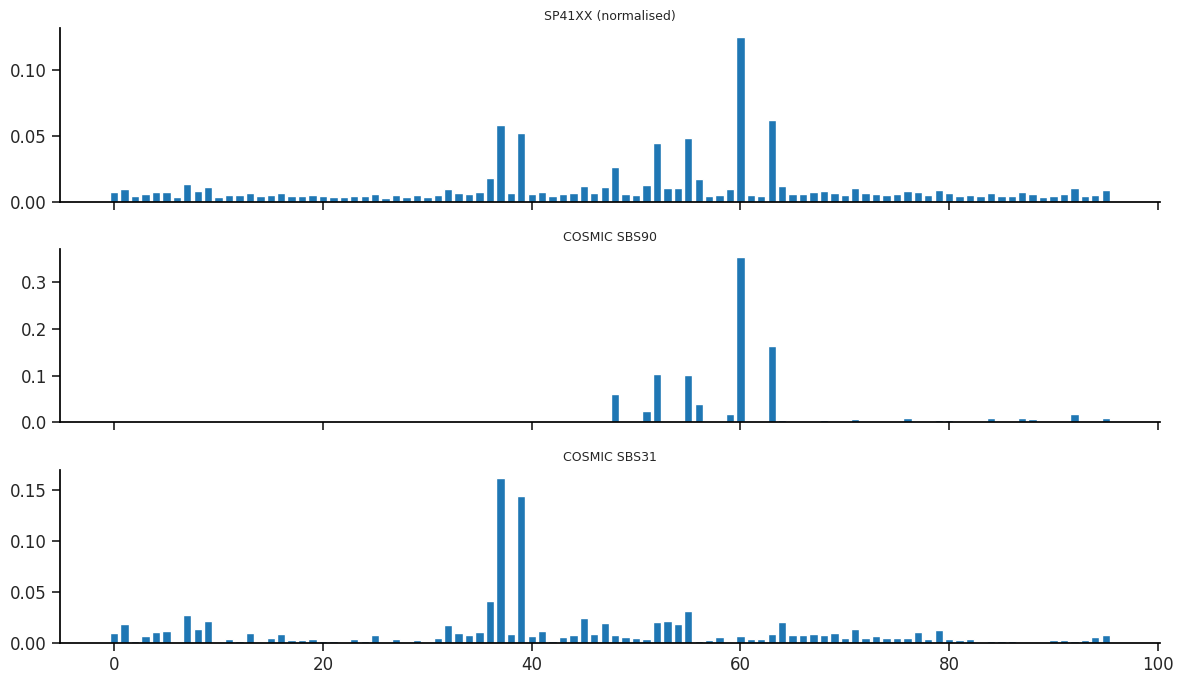

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, (v, t) in zip(axes, [(x / x.sum(), "SP41XX (normalised)"),
                             (catalog["SBS90"].values, "COSMIC SBS90"),
                             (catalog["SBS31"].values, "COSMIC SBS31")]):
    ax.bar(range(96), v); ax.set_title(t, fontsize=9)
plt.tight_layout(); plt.show()

In [28]:
def forward_nnls(x, catalog, min_gain=0.005, max_sigs=6):
    chosen, best, remaining = [], 0.0, list(catalog.columns)
    while remaining and len(chosen) < max_sigs:
        scores = {}
        for s in remaining:
            W = catalog[chosen + [s]].values
            w, _ = nnls(W, x)
            scores[s] = cosine(x, W @ w)
        s_best = max(scores, key=scores.get)
        if scores[s_best] - best < min_gain:
            break
        chosen.append(s_best); best = scores[s_best]; remaining.remove(s_best)
    w, _ = nnls(catalog[chosen].values, x)
    return pd.Series(w / w.sum(), index=chosen).round(3), round(best, 3)

forward_nnls(counts[OUTLIER].values.astype(float), catalog)

(SBS90    0.374
 SBS31    0.357
 SBS3     0.269
 dtype: float64,
 0.996)

## Q2.2 Answers:
SP41XX has 147722 SBSs and 97.5% of them are assigned to signature 2.  Using Non-Negative Least Squares（NNLS） decomposition, Signature 2 is mainly a combination of SBS90 (0.345) and SBS31 (0.338), plus small contributions from SBS39/SBS8/SBS9.. SBS90 refers to Duocarmycin exposure; T>A at TpTpA/TpTpT. SBS31 corresponds to prior chemotherapy treatment with platinum drugs. SBS90 and SBS31 are both treatment-related signatures, consistent with this post first-line-therapy sample: platinum agents  and duocarmycin-class alkylators.

We use the NNLS because it learns from the COSMIC reference instead of the data itself. NMF only learns from how exposures vary across samples. SBS31 and SBS90 show up exactly one sample. There is no variation in the data to tell the model there are two processes.




#Q2.3. Other than the outlier sample (SP41XX), the remaining breast cancers in the example dataset are untreated. Comment on the exposure of the signature from the treatment signature in other samples.

Absolute exposure:
 count     192.0
mean      272.4
std       322.1
min         0.0
25%        41.4
50%       151.3
75%       425.9
max      2092.0

Relative exposure:
 count    192.000
mean       0.036
std        0.025
min        0.000
25%        0.016
50%        0.032
75%        0.054
max        0.116

Samples with relative exposure >5%: 55  >10%: 2
Untreated samples with Sig2 below the paper's reliability limits: <5% of mutations: 137/192;  <=200 mutations: 111/192
Sig2 share of all mutations in the untreated cohort: 0.040  (SP41XX alone carries 143,967 Sig2 mutations vs 52,299 in all 192 untreated samples)


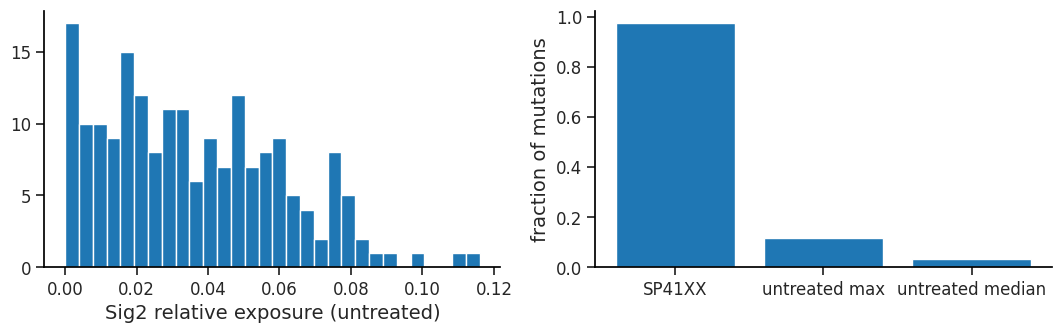

In [ ]:
# 1. Select Sig2 in the untreated samples

e2   = exposures.loc["Sig2", others]
r2   = rel.loc["Sig2", others]
print("Absolute exposure:\n", e2.describe().round(1).to_string())
print("\nRelative exposure:\n", r2.describe().round(3).to_string())
print("\nSamples with relative exposure >5%:", int((r2 > 0.05).sum()), " >10%:", int((r2 > 0.10).sum()))
print(f"Untreated samples with Sig2 below the paper's reliability limits: <5% of mutations: {int((r2 < 0.05).sum())}/{len(r2)};  <=200 mutations: {int((e2 <= 200).sum())}/{len(e2)}")
print(f"Sig2 share of all mutations in the untreated cohort: {e2.sum() / exposures[others].values.sum():.3f}  (SP41XX alone carries {exposures.loc['Sig2', OUTLIER]:,.0f} Sig2 mutations vs {e2.sum():,.0f} in all 192 untreated samples)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(r2, bins=30); axes[0].set_xlabel("Sig2 relative exposure (untreated)")
axes[1].bar(["SP41XX", "untreated max", "untreated median"],
            [rel.loc["Sig2", OUTLIER], r2.max(), r2.median()]); axes[1].set_ylabel("fraction of mutations")
plt.tight_layout(); plt.show()

The hallmark peak is missing. The signature peak T[T>A]A makes up 12.5% of SP41XX's mutations, but if untreated samples really carried 5-12% Sig2 this peak would be visibly raised in them. It is not (~1%).

In [ ]:
# re-run NMF without SP41XX. If untreated samples really contained SBS31/SBS90 processes, they should be recoverable on their own.

cmp = []
for k in [6, 7]:
    np.random.seed(0)
    m = salamander.KLNMF(n_signatures=k, max_iterations=10000); m.fit(counts[others])
    S_ = m.signatures
    cmp.append({"k": k,
                "best cos to Sig2":  round(max(cosine(signatures["Sig2"].values, S_[c].values) for c in S_), 3),
                "best cos to SBS31": round(max(cosine(catalog["SBS31"].values, S_[c].values) for c in S_), 3),
                "best cos to SBS90": round(max(cosine(catalog["SBS90"].values, S_[c].values) for c in S_), 3),
                "COSMIC best hits":  [catalog.columns[np.argmax([cosine(S_[c].values, catalog[q].values) for q in catalog])] for c in S_]})
pd.DataFrame(cmp)


,k,best cos to Sig2,best cos to SBS31,best cos to SBS90,COSMIC best hits
0,6,0.513,0.472,0.220,"[SBS2, SBS18, SBS13, SBS17b, SBS6, SBS3]"
1,7,0.565,0.488,0.289,"[SBS2, SBS8, SBS13, SBS17b, SBS1, SBS5, SBS18]"


Re-ran NMF without SP41XX: SBS31 and SBS90 are not recoverable using the untreated data.

In [ ]:
Xo = counts[others].values.astype(float)
e2v = exposures.loc["Sig2", others].values
print("Spearman(Sig2, total mutations) =", round(spearmanr(e2v, Xo.sum(0))[0], 2))
for s in signatures.columns:
    if s != "Sig2":
        print(f"  Spearman(Sig2, {s}) = {spearmanr(e2v, exposures.loc[s, others].values)[0]:.2f}")

Spearman(Sig2, total mutations) = 0.73
  Spearman(Sig2, Sig1) = 0.42
  Spearman(Sig2, Sig3) = 0.81
  Spearman(Sig2, Sig4) = 0.53
  Spearman(Sig2, Sig5) = 0.78
  Spearman(Sig2, Sig6) = -0.29
  Spearman(Sig2, Sig7) = 0.85


Signature 2 correlates with total mutation burden and with flat signatures. It may absorb residual counts rather than being an independent process.

In [ ]:
# Removing signature 2 on the fit (KL multiplicative-update refit. and replacing signature 2 with pure SBS31/SBS90)

def deviance(X, Y):
    Y = Y + 1e-12
    return 2 * np.sum(np.where(X > 0, X * np.log(np.maximum(X, 1e-12) / Y), 0) - X + Y, axis=0)

W_full = signatures.values;                  W_red = signatures.drop(columns="Sig2").values
H_full = kl_refit(W_full, Xo, 3000);         H_red = kl_refit(W_red, Xo, 3000)
d_dev  = deviance(Xo, W_red @ H_red) - deviance(Xo, W_full @ H_full)
cos_full = np.array([cosine(Xo[:, i], (W_full @ H_full)[:, i]) for i in range(Xo.shape[1])])
cos_red  = np.array([cosine(Xo[:, i], (W_red  @ H_red )[:, i]) for i in range(Xo.shape[1])])
print(f"Drop in reconstruction cosine after removing Sig2: median {np.median(cos_full-cos_red):.4f}, max {np.max(cos_full-cos_red):.4f}")
print(f"Median Poisson deviance increase {np.median(d_dev):.1f}; samples with increase >3.84: {int((d_dev>3.84).sum())}/{len(d_dev)}"
      " (note: real counts are overdispersed, so this test is optimistic)")

base = signatures.drop(columns="Sig2")
for name in ["SBS31", "SBS90"]:
    W = pd.concat([base, catalog[[name]]], axis=1).values
    H = kl_refit(W, Xo, 3000); f = H[-1] / H.sum(0)
    print(f"{name} refit fraction: median {np.median(f):.3f}, 90th percentile {np.percentile(f,90):.3f}, max {f.max():.3f}")


Drop in reconstruction cosine after removing Sig2: median 0.0009, max 0.0172
Median Poisson deviance increase 19.9; samples with increase >3.84: 134/192 (note: real counts are overdispersed, so this test is optimistic)
SBS31 refit fraction: median 0.019, 90th percentile 0.040, max 0.058
SBS90 refit fraction: median 0.011, 90th percentile 0.026, max 0.050


## Q2.3 answers:
The treatment-signature (SBS90 and SBS31) shold be considered as approximately zero in the untreated samples (excluding SP41XX). Signature 2 receives small non-zero exposure in untreated samples (median ~151 mutations (~3%)). Signature 2 correlates strongly with total burden and removing signature 2 barely change the reconstruction cosine.  Refitting with pure SBS31 and SBS90 gave fractions of only 2% or less. Based on the original paper (Alexandrov 2013) figure 3F, signatures contributing <5% of mutations are considered difficult to distinguish.
Together we conclude that treatment signature exposure in the untreated samples shold be regarded as approximately zero.


the hallmark T[T>A]A peak is not raised in untreated samples (~1% vs. 12.5% in SP41XX);
re-running NMF without SP41XX recovers nothing like Sig2, SBS31 or SBS90 (best cosine ≤ 0.57);
Sig2 also correlates strongly with the flat signatures (Sig7 0.85, Sig3 0.81, Sig5 0.78), which shows it is absorbing residual counts.



### 1. What the NMF fit reports
Taken at face value, KL-NMF assigns a small but non-zero Sig2 exposure to most untreated samples:

| Untreated samples (n = 192) | Value |
|---|---|
| Absolute Sig2 exposure | median 151 mutations (mean 272, max 2,092) |
| Relative Sig2 exposure | median 3.2% (mean 3.6%, max 11.6%) |
| Samples with > 5% / > 10% Sig2 | 55 / 2 |
| Below the reliability limits (< 5% of mutations / ≤ 200 mutations) | 137/192 / 111/192 |
| Sig2 share of all mutations in the untreated cohort | 4.0% (52,299 mutations, vs. 143,967 in SP41XX alone) |

The question is whether these small exposures reflect real exposure to the treatment-associated processes (SBS90/SBS31) or are an artefact of the fit.

### 2. Evidence that this is leakage, not real exposure
1. **The hallmark peak is missing.** T[T>A]A makes up ~12.5% of SP41XX's mutations. If untreated samples really carried 3–12% Sig2, this peak would be visibly raised in them; it is not (~1%).
2. **The signature cannot be recovered without SP41XX.** Re-running KL-NMF on the 192 untreated samples (k = 6 or 7) gives no signature resembling Sig2 (best cosine 0.51–0.57), SBS31 (0.47–0.49) or SBS90 (0.22–0.29). The extracted signatures map to SBS2, SBS13, SBS18/SBS8, SBS17b, SBS1/SBS6, SBS3 and SBS5. Sig2 exists only because of SP41XX.
3. **Sig2 exposure behaves like a residual, not an independent process.** In untreated samples it correlates with total mutation burden (Spearman 0.73) and strongly with the flat signatures Sig7/SBS3 (0.85), Sig3/SBS18 (0.81) and Sig5/SBS17b (0.78). A genuine treatment exposure has no reason to rise and fall with HRD or ROS signatures. This pattern fits Sig2 absorbing unexplained background counts.
4. **Removing Sig2 barely changes the fit.** Refitting the untreated samples without Sig2 lowers the reconstruction cosine by a median of 0.0009 (max 0.017).
5. **Pure treatment signatures receive almost no weight.** Replacing Sig2 with pure COSMIC SBS31 or SBS90 gives:
   - SBS31: median 1.9%, 90th percentile 4.0%, max 5.8%
   - SBS90: median 1.1%, 90th percentile 2.6%, max 5.0%

   These are at or below the ~5% level that is commonly treated as unreliable.
6. **Prior knowledge.** These patients were untreated, so there is no plausible source of platinum- or duocarmycin-induced mutations.

### 3. Reconciling the deviance test
Removing Sig2 increases the Poisson deviance by a median of 19.9, and 134/192 samples exceed the χ² threshold of 3.84. This looks like Sig2 "significantly" improves the fit. However:
- **Real mutation counts are overdispersed**, so a Poisson likelihood-ratio test is anti-conservative. With thousands of mutations per sample, even tiny improvements become "significant."
- **Sig2 is a composite with broad, flat components.** Any extra free signature can soak up residual noise and improve the likelihood slightly, without the corresponding process being present.
- **Statistical improvement is not biological presence.** The effect size is negligible (cosine change < 0.001 at the median), and none of the specific features of the treatment signatures appear.

### 4. Why the leakage happens
- SP41XX holds ~10% of all mutations in the cohort and has a unique profile. Under a KL/Poisson loss it dominates the fit and creates a signature of its own (Sig2).
- NMF exposures are constrained to be non-negative but are rarely exactly zero, and Sig2 contains broad components. So the model uses a little Sig2 in every sample to mop up whatever the other signatures don't explain.
- This phenomenon is known as **signature bleeding (leakage)**.

### 5. Conclusion
The exposure of untreated samples to the treatment signature (SBS90/SBS31) should be regarded as **effectively zero**. The small Sig2 exposures assigned by NMF (median ~3%) are fitting artefacts caused by the outlier, not evidence of treatment-induced mutagenesis. They should be reported as **"not detected (upper bound ~5%)"** rather than as measured exposures.

### 6. More rigorous approaches (future work)
- **Extract without the outlier, then refit.** Learn signatures from the untreated samples only, then refit SP41XX. This prevents the outlier from creating a signature that leaks into everyone else.
- **Per-sample presence test with overdispersion.** Use a negative-binomial likelihood-ratio test (or an mSigAct-style test) for whether adding SBS31/SBS90 is needed, instead of the Poisson test.
- **Bootstrap confidence intervals** on each sample's treatment-signature exposure, and check whether the lower bound includes zero.
- **Check the two samples with Sig2 > 10%** individually: their burden and whether they show any T[T>A]A enrichment.